# 🔑 Solutions · Lesson 03: Forecast Evaluation: Metrics, Baselines & Walk-Forward Validation

> Try every problem yourself first! Peek at hints before peeking here. Run the setup cell, then read each solution **and its explanation**: there is often more than one valid way.

In [1]:
import sys; sys.path.append("..")            # lets us import course_utils.py from the parent folder
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.tools.sm_exceptions         # (imported first: statsmodels registers its own warning filters on import)
import warnings; warnings.filterwarnings("ignore")   # keep the notebook readable; in real projects READ your warnings!
from course_utils import *                    # data loaders, metrics, plotting helpers, check()

### ✅ Solution 3.1 · Metrics by hand

**Problem recap:** Actual prices: `[100, 110, 120, 130]`. Forecasts: `[98, 115, 118, 140]`.
  Compute **MAE**, **RMSE** and **MAPE** using only NumPy (no helper functions). Store the MAE in `my_mae`.

In [2]:
y    = np.array([100, 110, 120, 130])
yhat = np.array([98, 115, 118, 140])
e = y - yhat
my_mae = np.mean(np.abs(e))
my_rmse = np.sqrt(np.mean(e ** 2))
my_mape = 100 * np.mean(np.abs(e / y))
print(f'MAE={my_mae:.3f}  RMSE={my_rmse:.3f}  MAPE={my_mape:.2f}%')
check('MAE', my_mae, 4.75)

MAE=4.750  RMSE=5.766  MAPE=3.98%
✅ MAE: correct!


**Why this works:** RMSE (5.77) > MAE (4.75) because of the single large error of −10: squaring punishes big misses. When RMSE is much larger than MAE, a few large errors dominate.

### ✅ Solution 3.2 · The MAPE trap

**Problem recap:** The raw daily file has a `rainfall_mm` column where **82 %** of days are *exactly* zero. Take the last 60 values of daily rainfall as `actual`
  and forecast them with the average of the *previous* 60 days (a flat forecast).
  (a) Compute MAPE with `course_utils.mape`: what happens? (b) Compute MAE and sMAPE instead. (c) In a comment, explain why MAPE fails and
  name two situations in *agricultural* forecasting where this could bite.

In [3]:
rain = pd.read_csv(DATA / 'maize_daily_raw.csv')['rainfall_mm'].values
actual = rain[-60:]
fc = np.full(60, rain[-120:-60].mean())
print('zeros in actual:', int((actual == 0).sum()), 'of 60')
print('MAPE :', mape(actual, fc), ' <- NaN by design: undefined when any actual is 0')
print('MAE  :', round(mae(actual, fc), 3))
print('sMAPE:', round(smape(actual, fc), 1), '%')

zeros in actual: 47 of 60
MAPE : nan  <- NaN by design: undefined when any actual is 0
MAE  : 2.085
sMAPE: 190.2 %


**Why this works:** MAPE is undefined at zero and explodes near zero (an actual of 0.1 mm against a forecast of 5 mm is a 4900 % 'error'). Note that sMAPE is *not* a rescue here either: every day with actual 0 and a non-zero forecast scores the maximum 200 %, so its 190 % is meaningless. Use MAE/RMSE (or the scale-free MASE) for intermittent or near-zero series. Even for prices, MAPE is **asymmetric**: it penalises over-forecasts more than under-forecasts.

### ✅ Solution 3.3 · Which baseline wins for onion?

**Problem recap:** Hold out the last **52 weeks** of **onion** prices. Using the functions `fc_naive`, `fc_mean`, `fc_drift`, `fc_snaive`, forecast all 52 weeks from the end of the training data
  and print a `score_table`. Which baseline wins and why? Then create the plot with `plot_forecasts`.

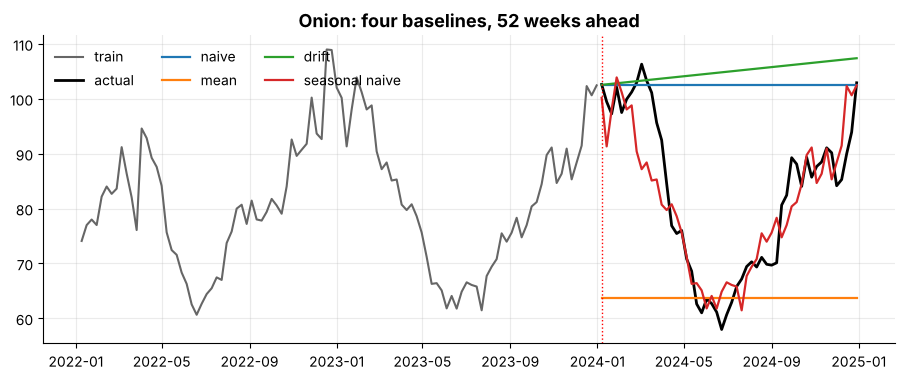

,MAE,RMSE,MAPE,sMAPE,MASE
seasonal naive,4.889,6.530,5.778,5.858,0.619
mean,19.286,23.524,21.212,24.838,2.443
naive,20.314,24.708,28.629,23.317,2.573
drift,22.727,26.995,31.729,25.578,2.879


In [4]:
s = load_weekly('onion')['price']
train, test = s.iloc[:-52], s.iloc[-52:]
fcs = {'naive': fc_naive(train, 52), 'mean': fc_mean(train, 52), 'drift': fc_drift(train, 52), 'seasonal naive': fc_snaive(train, 52)}
plot_forecasts(train, test, fcs, 'Onion: four baselines, 52 weeks ahead'); plt.show()
score_table(test, fcs, y_train=train, m=52)

**Why this works:** Onion has the strongest seasonality of our four crops (Lesson 1), so repeating last year's pattern (seasonal naive) beats any flat line over a 52-week horizon. A good practitioner *always* tests a seasonal baseline when the data is seasonal.

### ✅ Solution 3.4 · Walk-forward for rice

**Problem recap:** Run a walk-forward evaluation on **rice** with `walk_forward(..., initial=400, horizon=4, step=4)` for `fc_naive` and `fc_drift`.
  Report the overall MAE for each and the MAE **by horizon** (1–4 weeks). Does the error grow with horizon?

In [5]:
s = load_weekly('rice')['price']
res = {}
for name, f in {'naive': fc_naive, 'drift': fc_drift}.items():
    wf = walk_forward(s, f, initial=400, horizon=4, step=4)
    res[name] = scores_by_horizon(wf)['MAE']
    print(f"{name:<6} overall MAE = {mae(wf.actual, wf.forecast):.3f}")
pd.DataFrame(res).rename_axis('horizon (weeks)')

naive  overall MAE = 3.155
drift  overall MAE = 3.173


,naive,drift
horizon (weeks),,
1,1.777679,1.775738
2,2.411250,2.436351
3,3.628571,3.661020
4,4.801071,4.820847


**Why this works:** Errors grow with the horizon: predicting further ahead is harder because uncertainty accumulates. A single-number score hides this, which is why the horizon breakdown matters.

### ✅ Solution 3.5 · Reproduce the 'too good to be true' result

**Problem recap:** Re-run the leakage experiment of the worked example for **rice** (instead of maize): horizon `h=12`, features = lags (12, 13, 14, 26, 52), Fourier calendar terms and a time index `t`; model = `RandomForestRegressor(200, random_state=0)`.
  Compare the MAE from a **random** 80/20 split with a **chronological** 80/20 split, and with the naive-12 baseline on each test set.
  Write a two-sentence explanation of what you found and why the random split is invalid. **Bonus:** repeat for tomato (no trend). The gap is much smaller: why?

In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
rice = load_weekly('rice')
X, y = make_features(rice, lags=(12, 13, 14, 26, 52), windows=(), h=12)
X['t'] = np.arange(len(X))
d = X.join(y.rename('y')).dropna(); Xd, yd = d.drop(columns='y'), d['y']
Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=.2, shuffle=True, random_state=0)
rf = RandomForestRegressor(200, random_state=0).fit(Xtr, ytr)
print('RANDOM split      MAE:', round(mae(yte, rf.predict(Xte)), 2), '| naive-12 on same rows:', round(mae(yte, Xte['price_lag_12']), 2))
k = int(len(d) * .8)
rf = RandomForestRegressor(200, random_state=0).fit(Xd.iloc[:k], yd.iloc[:k])
print('CHRONOLOGICAL     MAE:', round(mae(yd.iloc[k:], rf.predict(Xd.iloc[k:])), 2), '| naive-12 on same rows:', round(mae(yd.iloc[k:], Xd.iloc[k:]['price_lag_12']), 2))

RANDOM split      MAE: 1.84 | naive-12 on same rows: 6.47


CHRONOLOGICAL     MAE: 8.14 | naive-12 on same rows: 6.99


**Why this works:** With a shuffled split, every test week has training weeks on both sides of it (t−1 and t+1), so the forest can effectively *look up* the answer through the time index and the calendar features. The honest chronological score is what the model would achieve in production, and for rice it is about 4× worse: even worse than the naive baseline, because a forest cannot extrapolate the upward trend (Lesson 6). **Bonus answer:** tomato has no strong trend, so the forest is rarely asked to leave its training range and the extrapolation problem mostly disappears; only the (smaller) neighbour-leak remains.